In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

zip_path = "/content/drive/MyDrive/Plant_Disease_Project/archive (7).zip"

print("File exists:", os.path.exists(zip_path))

File exists: True


In [ ]:
import zipfile
import os

extract_path = "/content/plant_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
class_folders = []

for root, dirs, files in os.walk(extract_path):
    if len(dirs) >= 10:
        class_folders.append((root, dirs))

for root, folders in class_folders:
    print("Dataset path:", root)
    print("Total categories:", len(folders))
    print("\nCategory names:")

    for folder in folders:
        print(folder)

Dataset path: /content/plant_dataset/PlantVillage
Total categories: 15

Category names:
Tomato_Late_blight
Tomato__Tomato_mosaic_virus
Tomato_Septoria_leaf_spot
Tomato__Target_Spot
Tomato__Tomato_YellowLeaf__Curl_Virus
Tomato_Early_blight
Tomato_Bacterial_spot
Pepper__bell___healthy
Tomato_Leaf_Mold
Potato___Early_blight
Tomato_Spider_mites_Two_spotted_spider_mite
Potato___healthy
Tomato_healthy
Pepper__bell___Bacterial_spot
Potato___Late_blight


In [ ]:
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp')

total_images = 0

for root, dirs, files in os.walk(extract_path):
    count = sum(
        file.lower().endswith(image_extensions)
        for file in files
    )
    total_images += count

print("Total Images:", total_images)

Total Images: 20638


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
DATA_DIR = Path(extract_path)

image_extensions = {'.jpg', '.jpeg', '.png', '.bmp'}

class_dirs = [
    folder for folder in DATA_DIR.rglob("*")
    if folder.is_dir()
    and any(
        file.is_file() and file.suffix.lower() in image_extensions
        for file in folder.iterdir()
    )
]

print("Total Classes:", len(class_dirs))

for folder in sorted(class_dirs):
    print(folder.name)

Total Classes: 15
Pepper__bell___Bacterial_spot
Pepper__bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Tomato_Bacterial_spot
Tomato_Early_blight
Tomato_Late_blight
Tomato_Leaf_Mold
Tomato_Septoria_leaf_spot
Tomato_Spider_mites_Two_spotted_spider_mite
Tomato__Target_Spot
Tomato__Tomato_YellowLeaf__Curl_Virus
Tomato__Tomato_mosaic_virus
Tomato_healthy


In [ ]:
image_counts = {}

for folder in class_dirs:
    count = sum(
        file.suffix.lower() in image_extensions
        for file in folder.iterdir()
        if file.is_file()
    )
    image_counts[folder.name] = count

for name, count in image_counts.items():
    print(name, ":", count)

print("\nTotal Images:", sum(image_counts.values()))

Tomato_Late_blight : 1909
Tomato__Tomato_mosaic_virus : 373
Tomato_Septoria_leaf_spot : 1771
Tomato__Target_Spot : 1404
Tomato__Tomato_YellowLeaf__Curl_Virus : 3208
Tomato_Early_blight : 1000
Tomato_Bacterial_spot : 2127
Pepper__bell___healthy : 1478
Tomato_Leaf_Mold : 952
Potato___Early_blight : 1000
Tomato_Spider_mites_Two_spotted_spider_mite : 1676
Potato___healthy : 152
Tomato_healthy : 1591
Pepper__bell___Bacterial_spot : 997
Potato___Late_blight : 1000

Total Images: 20638


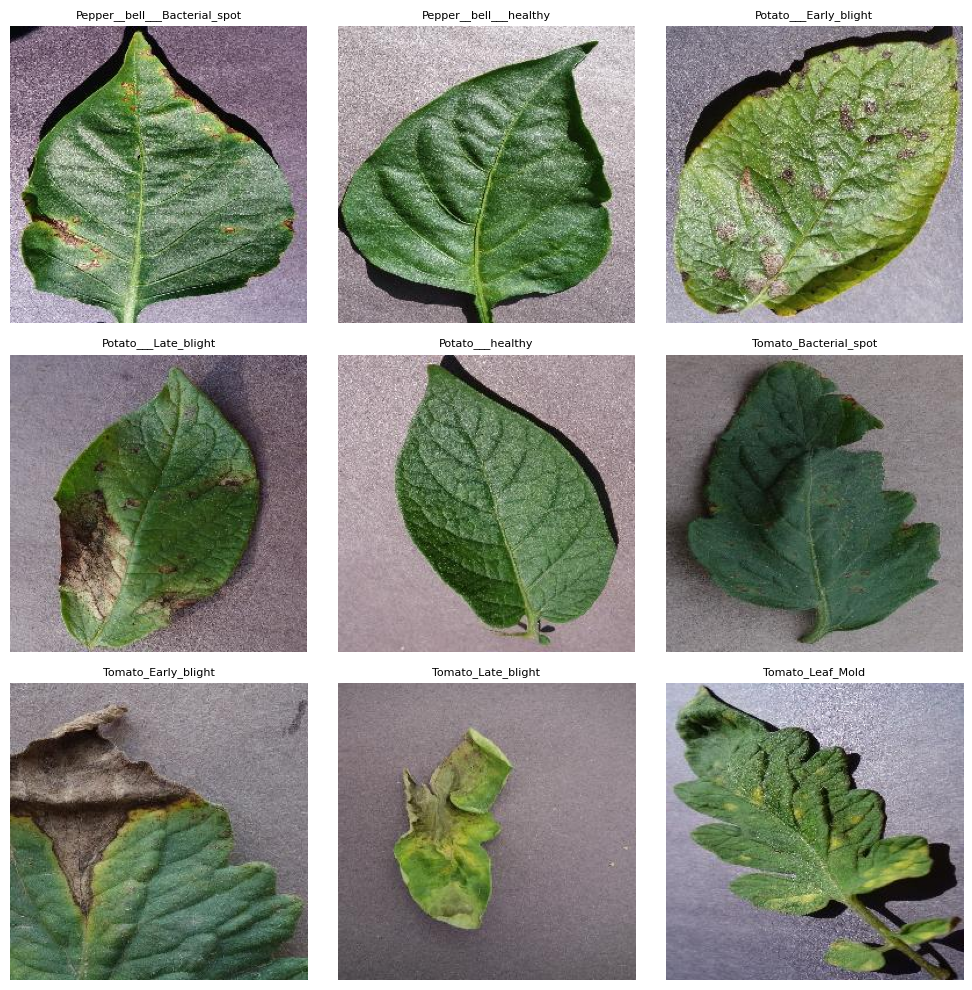

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

sample_folders = sorted(class_dirs)[:9]

for ax, folder in zip(axes.flat, sample_folders):
    images = [
        f for f in folder.iterdir()
        if f.suffix.lower() in image_extensions
    ]

    if images:
        img = plt.imread(str(images[0]))
        ax.imshow(img)
        ax.set_title(folder.name, fontsize=8)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
data = []

for folder in class_dirs:
    for file in folder.iterdir():
        if file.suffix.lower() in image_extensions:
            data.append({
                "path": str(file),
                "label": folder.name
            })

df = pd.DataFrame(data)

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images:", len(test_df))

Training Images: 14446
Validation Images: 3096
Testing Images: 3096


In [ ]:
IMG_SIZE = 128
BATCH_SIZE = 32

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    return image, label

class_names = sorted(df["label"].unique())

label_to_index = {
    name: index for index, name in enumerate(class_names)
}

def make_dataset(dataframe, training=False):
    paths = dataframe["path"].values
    labels = dataframe["label"].map(label_to_index).values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

    if training:
        ds = ds.shuffle(1000)

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("All datasets prepared successfully!")
print("Classes:", len(class_names))

All datasets prepared successfully!
Classes: 15


In [ ]:
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(128, 128, 3)),

    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Dense(len(class_names), activation='softmax')
])

print("CNN Model Created Successfully!")

CNN Model Created Successfully!


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,306,575 (12.61 MB)

 Trainable params: 3,306,575 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model Compiled Successfully!")

Model Compiled Successfully!


In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

Epoch 1/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 38s 62ms/step - accuracy: 0.4673 - loss: 1.6560 - val_accuracy: 0.7183 - val_loss: 0.8860
Epoch 2/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.6820 - loss: 0.9605 - val_accuracy: 0.8091 - val_loss: 0.5808
Epoch 3/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 14s 30ms/step - accuracy: 0.7444 - loss: 0.7585 - val_accuracy: 0.8366 - val_loss: 0.5047
Epoch 4/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 14s 30ms/step - accuracy: 0.7874 - loss: 0.6268 - val_accuracy: 0.8689 - val_loss: 0.3898
Epoch 5/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.8166 - loss: 0.5362 - val_accuracy: 0.8595 - val_loss: 0.4237
Epoch 6/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 14s 30ms/step - accuracy: 0.8389 - loss: 0.4754 - val_accuracy: 0.8556 - val_loss: 0.3936
Epoch 7/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 21s 32ms/step - accuracy: 0.8636 - loss: 0.4046 - val_accuracy: 0.8866 - val_loss: 0.3447
Epoch 8/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.8735 - loss: 0.3742 - 

In [ ]:
model.save('/content/plant_disease_cnn.keras')

print("Model Saved Successfully!")

Model Saved Successfully!


In [20]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

97/97 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.9209 - loss: 0.2986
Test Loss: 0.2985761761665344
Test Accuracy: 92.09 %


In [21]:
from sklearn.metrics import classification_report

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

97/97 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.94      0.92      0.93       149
                     Pepper__bell___healthy       0.94      0.96      0.95       221
                      Potato___Early_blight       0.92      0.97      0.94       150
                       Potato___Late_blight       0.91      0.85      0.88       150
                           Potato___healthy       1.00      0.57      0.72        23
                      Tomato_Bacterial_spot       0.95      0.99      0.97       319
                        Tomato_Early_blight       0.79      0.78      0.79       150
                         Tomato_Late_blight       0.88      0.87      0.87       287
                           Tomato_Leaf_Mold       0.91      0.88      0.90       143
                  Tomato_Septoria_leaf_spot       0.84      0.94      0.89       266
Tomato_Spider_mites_Two_

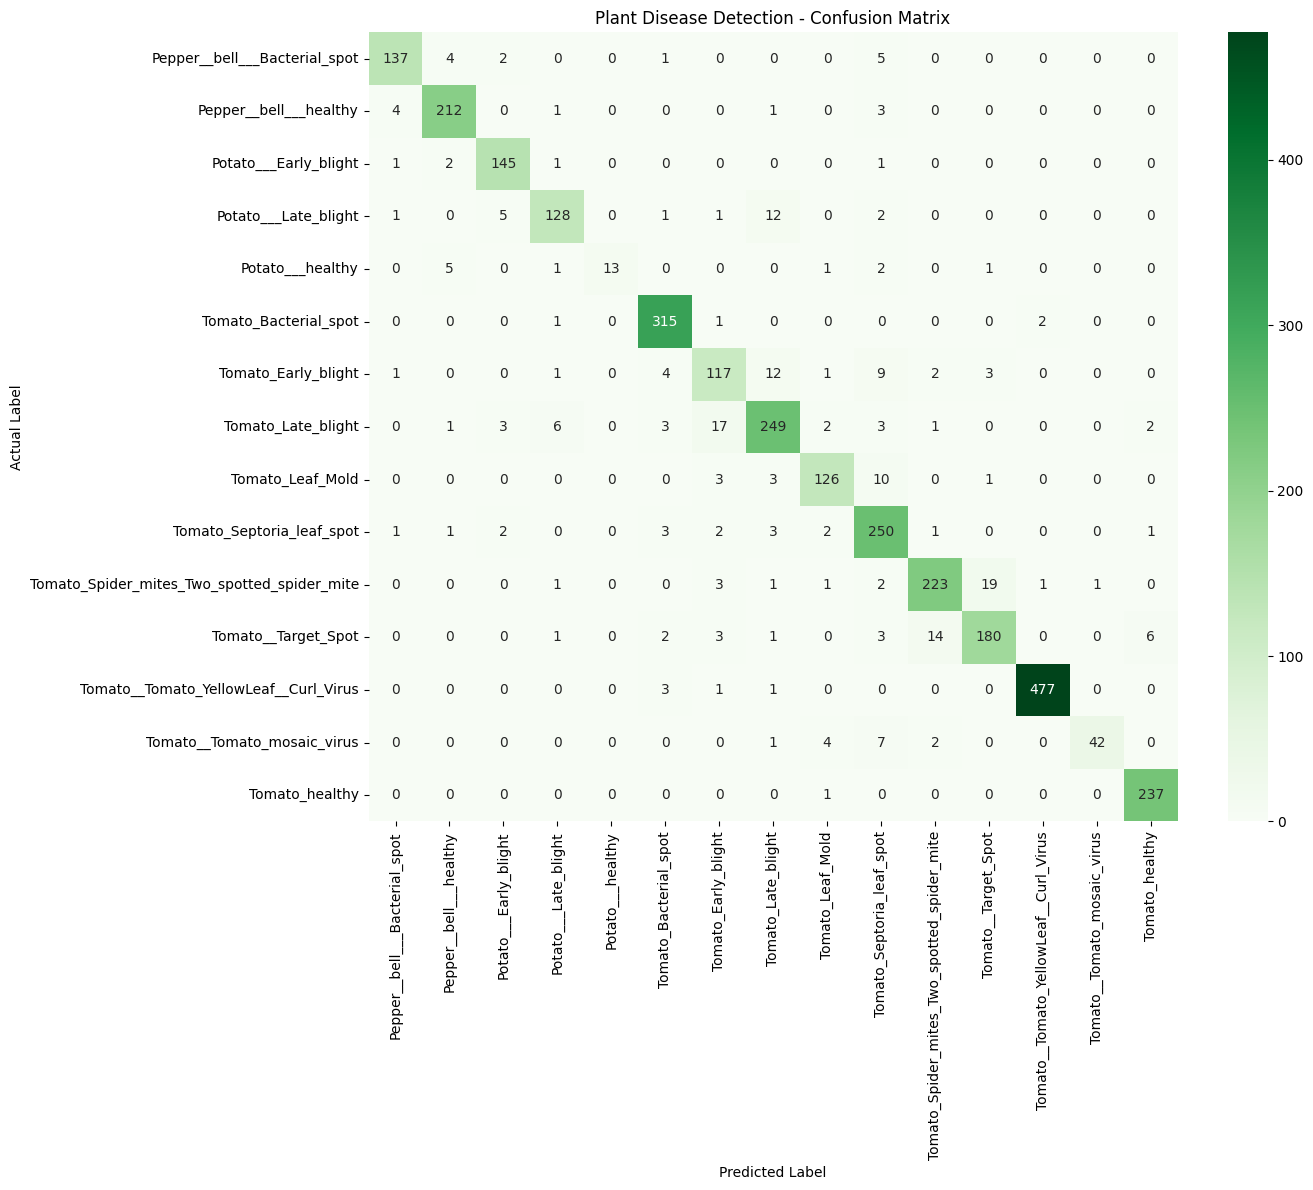

In [22]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Plant Disease Detection - Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

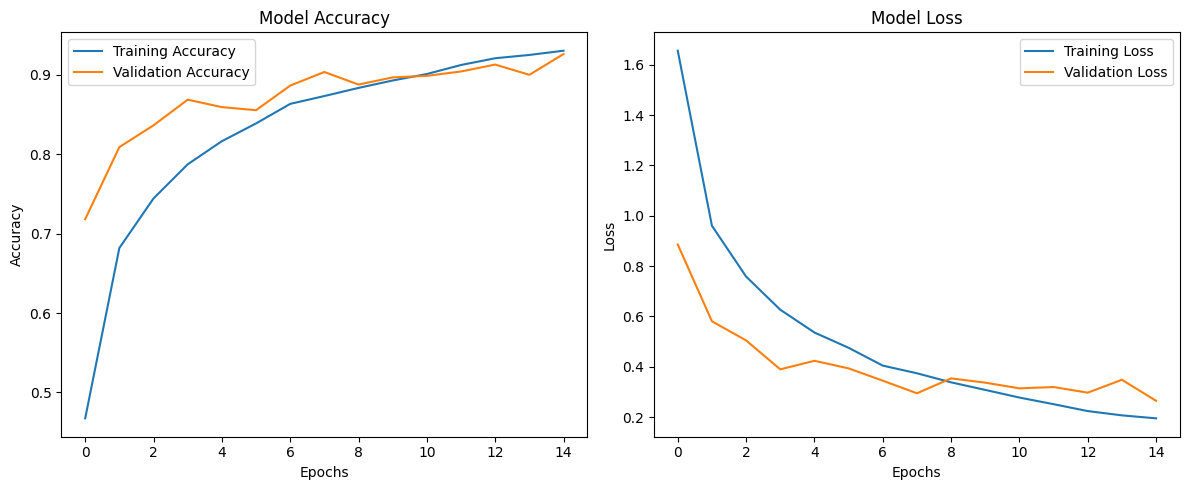

In [23]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [24]:
import json
import os

save_dir = "/content/drive/MyDrive/Plant_Disease_Project/Results"
os.makedirs(save_dir, exist_ok=True)

model.save(os.path.join(save_dir, "plant_disease_cnn.keras"))

with open(os.path.join(save_dir, "class_names.json"), "w") as f:
    json.dump(class_names, f)

print("Model and class names saved successfully!")

Model and class names saved successfully!


In [25]:
from google.colab import files

uploaded = files.upload()

Saving HGIC-tomato-cold injury-600x496.jpg to HGIC-tomato-cold injury-600x496.jpg


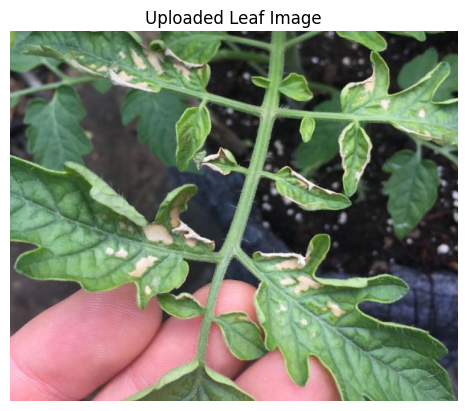

In [26]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = list(uploaded.keys())[0]

img = Image.open(image_path).convert("RGB")

plt.imshow(img)
plt.title("Uploaded Leaf Image")
plt.axis("off")
plt.show()

In [27]:
img = tf.keras.utils.load_img(
    image_path,
    target_size=(128, 128)
)

img_array = tf.keras.utils.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

predicted_index = np.argmax(prediction[0])
predicted_class = class_names[predicted_index]

confidence = prediction[0][predicted_index] * 100

print("Predicted Disease:", predicted_class)
print("Model Score:", round(float(confidence), 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted Disease: Tomato_Late_blight
Model Score: 99.46 %


In [28]:
top_indices = np.argsort(prediction[0])[-3:][::-1]

print("Top 3 Predictions:\n")

for index in top_indices:
    print(
        class_names[index],
        ":", round(float(prediction[0][index] * 100), 2), "%"
    )

Top 3 Predictions:

Tomato_Late_blight : 99.46 %
Tomato_Septoria_leaf_spot : 0.33 %
Tomato_Early_blight : 0.12 %


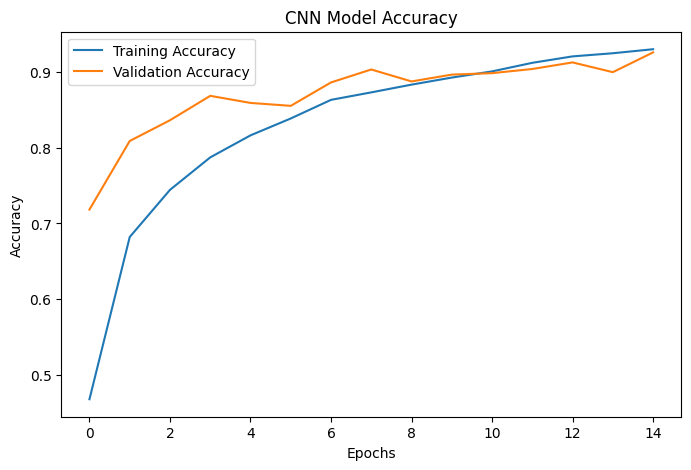

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("CNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.savefig(
    "/content/drive/MyDrive/Plant_Disease_Project/Results/accuracy_graph.png"
)
plt.show()

In [30]:
import json

results = {
    "test_accuracy": float(test_accuracy),
    "test_loss": float(test_loss),
    "total_classes": len(class_names),
    "model": "CNN",
    "image_size": "128x128"
}

results_path = "/content/drive/MyDrive/Plant_Disease_Project/Results/evaluation_results.json"

with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!
